C:\Users\youss\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 325M/325M [01:41<00:00, 3.35MB/s] 

Extracting files...


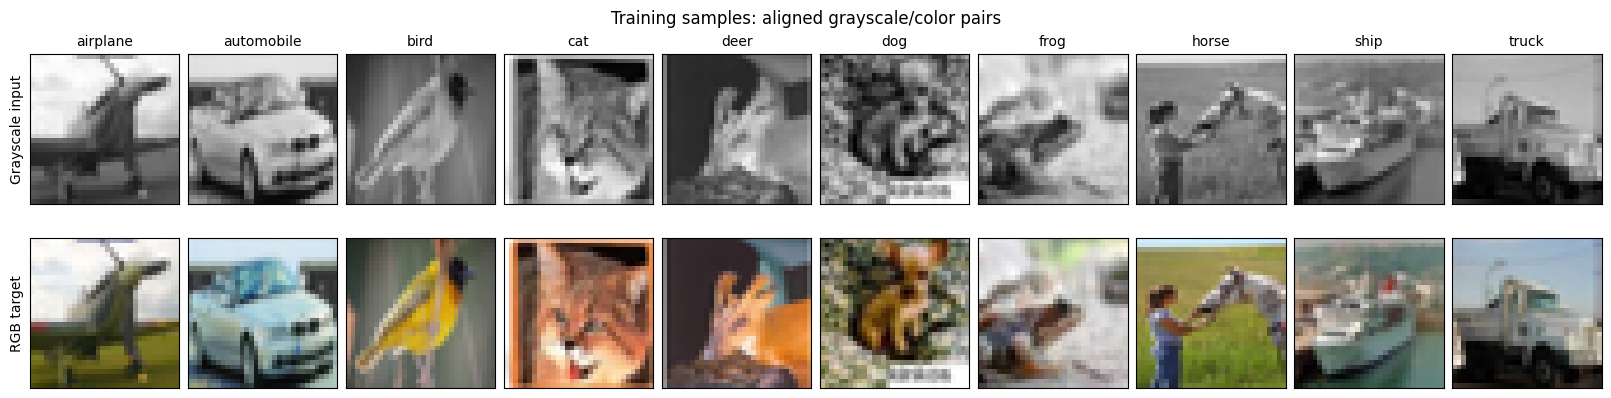

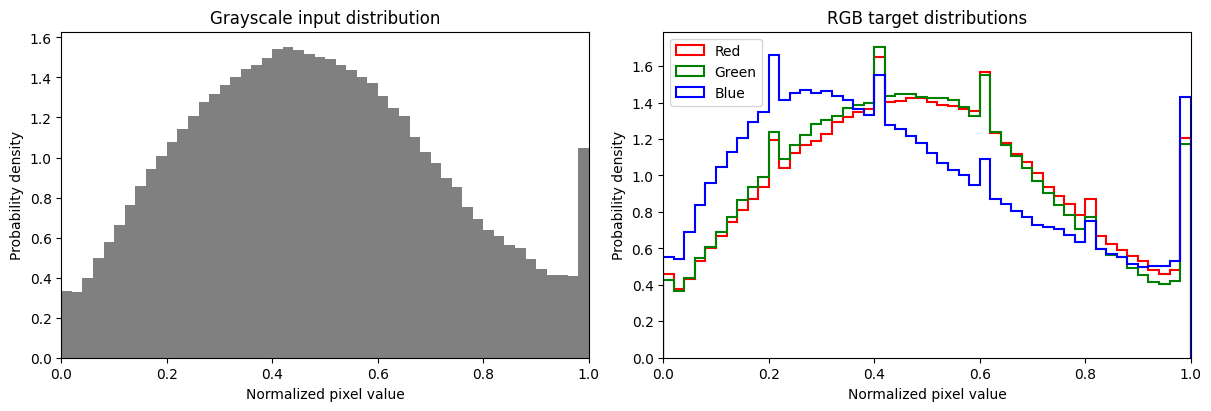

Dataset: balanced CIFAR-10 subset, 5,000 images, 32x32 RGB
Training: X=(3500, 1024), Y=(3500, 3072); per-class counts=[350 350 350 350 350 350 350 350 350 350]
Validation: X=(1000, 1024), Y=(1000, 3072); per-class counts=[100 100 100 100 100 100 100 100 100 100]
Testing: X=(500, 1024), Y=(500, 3072); per-class counts=[50 50 50 50 50 50 50 50 50 50]
Training batches: 35, batch size: 100
Grayscale range: [0.0000, 1.0000]
RGB range: [0.0000, 1.0000]


In [2]:
#1
#Dataset, Preprocessing, and Splitting
#Choose CIFAR-10, normalize and visualize grayscale/RGB pairs, split 70/20/10, and create batches of 100.

import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import pickle
from pathlib import Path

# Dataset documentation: https://keras.io/api/datasets/cifar10/

SEED = 42
SAMPLES_PER_CLASS = 500
IMAGE_SIZE = 32
BATCH_SIZE = 100
rng = np.random.default_rng(SEED)
class_names = np.array([
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
])

# Load CIFAR-10 through KaggleHub / Colab's dataset cache.
# Use the original training pool only; create our own 70/20/10 splits below.
path = kagglehub.dataset_download("pankrzysiu/cifar10-python")
batch_files = sorted(Path(path).rglob("data_batch_*")) # Sort all batch files
assert len(batch_files) == 5, f"Expected 5 training files in {path}"

image_parts, label_parts = [], []
for file in batch_files:
    with open(file, "rb") as f:
        batch = pickle.load(f, encoding="bytes")
    image_parts.append(batch[b"data"])
    label_parts.extend(batch[b"labels"])

# CIFAR stores channels separately; convert to (images, height, width, RGB).
source_rgb = (
    np.concatenate(image_parts)
    .reshape(-1, 3, IMAGE_SIZE, IMAGE_SIZE)
    .transpose(0, 2, 3, 1)
)
source_labels = np.array(label_parts)
del image_parts, label_parts, batch # Delete unwanted read files. We already copied them over

# Select 500 distinct images per class: a balanced 5,000-image working dataset.
selected_indices = np.concatenate([
    rng.choice(np.flatnonzero(source_labels == c), SAMPLES_PER_CLASS, replace=False)
    for c in range(len(class_names))
])
rng.shuffle(selected_indices)
labels = source_labels[selected_indices]

# Convert uint8 pixels to float32 in [0, 1].
color_images = source_rgb[selected_indices].astype(np.float32) / 255.0
del source_rgb, source_labels #Delete unwanted files.

# Standard weighted RGB-to-grayscale conversion (BT.601 luma weights).
# Each grayscale image and its RGB target remain at the same array index.
gray_images = color_images @ np.array([0.299, 0.587, 0.114], dtype=np.float32)

# Split within each class: 350 train, 100 validation, 50 test images.
# Fixed seeds make selection and splitting reproducible; no image crosses splits.
train_parts, val_parts, test_parts = [], [], []
for c in range(len(class_names)):
    indices = np.flatnonzero(labels == c)
    rng.shuffle(indices)
    n_train = int(0.70 * len(indices))
    n_val = int(0.20 * len(indices))
    train_parts.append(indices[:n_train])
    val_parts.append(indices[n_train:n_train + n_val])
    test_parts.append(indices[n_train + n_val:])

train_idx = rng.permutation(np.concatenate(train_parts))
val_idx = rng.permutation(np.concatenate(val_parts))
test_idx = rng.permutation(np.concatenate(test_parts))

# X contains 5000 grayscale images, each with 1024 grayscale values.
# Y contains 5000 rgb images, each with 3072 RGB target values.
# X[0,0] returns gray intensity of pixel 0 in image 0.
# Y[0,0] returns red intensity of pixel 0 in image 0, Y[0,1] = green pixel 0,
# Y[0,2] = blue pixel 0, and eg. Y[0,5] = blue pixel 1; X[0,1] = gray pixel 1.
X = gray_images.reshape(len(labels), IMAGE_SIZE * IMAGE_SIZE)
Y = color_images.reshape(len(labels), IMAGE_SIZE * IMAGE_SIZE * 3)
X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
X_test, Y_test = X[test_idx], Y[test_idx]
labels_train, labels_val, labels_test = labels[train_idx], labels[val_idx], labels[test_idx]

# Sanity-check normalization, pairing, exact proportions, and unique membership.
assert X.dtype == Y.dtype == np.float32
assert np.isfinite(X).all() and np.isfinite(Y).all()
assert 0 <= X.min() <= X.max() <= 1
assert 0 <= Y.min() <= Y.max() <= 1
assert len(np.unique(selected_indices)) == 5000
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == 5000
assert (len(train_idx), len(val_idx), len(test_idx)) == (3500, 1000, 500)
assert np.allclose(X_train.reshape(-1, IMAGE_SIZE, IMAGE_SIZE),
                   Y_train.reshape(-1, IMAGE_SIZE, IMAGE_SIZE, 3) @ np.array([0.299, 0.587, 0.114], dtype=np.float32))

# Show one training example per class. Keep validation/test images for later use.
fig, axes = plt.subplots(2, 10, figsize=(16, 4), constrained_layout=True)
for c in range(len(class_names)):
    display_index = np.random.default_rng().integers(0, 350)
    i = train_idx[np.flatnonzero(labels_train == c)[display_index]]
    axes[0, c].imshow(gray_images[i], cmap='gray', vmin=0, vmax=1)
    axes[1, c].imshow(color_images[i])
    axes[0, c].set_title(class_names[c], fontsize=10)
    for row in range(2):
        axes[row, c].set_xticks([])
        axes[row, c].set_yticks([])
axes[0, 0].set_ylabel('Grayscale input')
axes[1, 0].set_ylabel('RGB target')
fig.suptitle('Training samples: aligned grayscale/color pairs')
plt.show()

# Plot training pixel distributions with common bins on the normalized scale.
bins = np.linspace(0, 1, 51)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(X_train.ravel(), bins=bins, color='gray', density=True)
axes[0].set_title('Grayscale input distribution')
train_rgb = Y_train.reshape(-1, IMAGE_SIZE, IMAGE_SIZE, 3)
for channel, name, color in zip(range(3), ['Red', 'Green', 'Blue'], ['red', 'green', 'blue']):
    axes[1].hist(train_rgb[..., channel].ravel(), bins=bins,
                 histtype='step', color=color, label=name, density=True, linewidth=1.5)
axes[1].set_title('RGB target distributions')
axes[1].legend()
for ax in axes:
    ax.set_xlabel('Normalized pixel value')
    ax.set_ylabel('Probability density')
    ax.set_xlim(0, 1)
plt.show()

# The already-shuffled training set divides exactly into 35 batches of 100.
assert len(X_train) % BATCH_SIZE == 0
X_train_batches = X_train.reshape(-1, BATCH_SIZE, X_train.shape[1])
Y_train_batches = Y_train.reshape(-1, BATCH_SIZE, Y_train.shape[1])
train_batches = list(zip(X_train_batches, Y_train_batches))
assert len(train_batches) == 35
assert all(xb.shape == (100, 1024) and yb.shape == (100, 3072)
           for xb, yb in train_batches)

# Later tasks can use: for X_batch, Y_batch in train_batches: ...
# For fresh epoch shuffling, apply the SAME permutation to X_train and Y_train,
# then recreate the batch views. Do not train on validation/test data.
print('Dataset: balanced CIFAR-10 subset, 5,000 images, 32x32 RGB')
for name, inputs, targets, split_labels in [
    ('Training', X_train, Y_train, labels_train),
    ('Validation', X_val, Y_val, labels_val),
    ('Testing', X_test, Y_test, labels_test)
]:
    print(f'{name}: X={inputs.shape}, Y={targets.shape}; per-class counts={np.bincount(split_labels)}')
print(f'Training batches: {len(train_batches)}, batch size: {BATCH_SIZE}')
print(f'Grayscale range: [{X.min():.4f}, {X.max():.4f}]')
print(f'RGB range: [{Y.min():.4f}, {Y.max():.4f}]')


In [3]:
import numpy as np


class Colorizer:
    def __init__(self, input_size, output_size, hidden_size=32, seed=42):
        rng = np.random.default_rng(seed)

        self.hidden_weights = rng.normal(
            0, 1 / np.sqrt(input_size), (input_size, hidden_size)
        )
        self.hidden_bias = rng.normal(0, 0.01, hidden_size)
        self.output_weights = rng.normal(
            0, 1 / np.sqrt(hidden_size), (hidden_size, output_size)
        )
        self.output_bias = rng.normal(0, 0.01, output_size)

    def forward(self, grayscale):
        hidden_scores = grayscale @ self.hidden_weights + self.hidden_bias
        hidden = np.maximum(0, hidden_scores)

        color_scores = hidden @ self.output_weights + self.output_bias
        return 1 / (1 + np.exp(-np.clip(color_scores, -60, 60)))


image_size = 16
pixel_count = image_size * image_size
model = Colorizer(input_size=pixel_count, output_size=3 * pixel_count)
sample_images = np.stack([np.zeros(pixel_count), np.ones(pixel_count)])
predictions = model.forward(sample_images)
print("Grayscale batch:", sample_images.shape)
print("RGB predictions:", predictions.shape)


Grayscale batch: (2, 256)
RGB predictions: (2, 768)


In [4]:
#3
#Backpropagation, Implemented From Scratch
#Train the Task 2 network with explicit forward, backward, and gradient-descent steps.

class TrainableColorizer(Colorizer):
    """The Task 2 network with manually implemented backpropagation."""

    def forward_with_cache(self, grayscale):
        hidden_scores = grayscale @ self.hidden_weights + self.hidden_bias
        hidden = np.maximum(0, hidden_scores)
        color_scores = hidden @ self.output_weights + self.output_bias
        predictions = 1 / (1 + np.exp(-np.clip(color_scores, -60, 60)))
        return predictions, (grayscale, hidden_scores, hidden, predictions)

    @staticmethod
    def mean_squared_error(predictions, targets):
        return np.mean((predictions - targets) ** 2)

    def backward(self, targets, cache):
        grayscale, hidden_scores, hidden, predictions = cache
        # Derivative of MSE, followed by the sigmoid derivative.
        d_predictions = 2 * (predictions - targets) / targets.size
        d_color_scores = d_predictions * predictions * (1 - predictions)

        # Gradients for the output affine layer.
        output_gradient = hidden.T @ d_color_scores
        output_bias_gradient = d_color_scores.sum(axis=0)

        # Propagate through the output layer and ReLU to the hidden layer.
        d_hidden = d_color_scores @ self.output_weights.T
        d_hidden_scores = d_hidden * (hidden_scores > 0)
        hidden_gradient = grayscale.T @ d_hidden_scores
        hidden_bias_gradient = d_hidden_scores.sum(axis=0)

        return {
            'hidden_weights': hidden_gradient,
            'hidden_bias': hidden_bias_gradient,
            'output_weights': output_gradient,
            'output_bias': output_bias_gradient,
        }

    def apply_gradients(self, gradients, learning_rate):
        self.hidden_weights -= learning_rate * gradients['hidden_weights']
        self.hidden_bias -= learning_rate * gradients['hidden_bias']
        self.output_weights -= learning_rate * gradients['output_weights']
        self.output_bias -= learning_rate * gradients['output_bias']


def evaluate(model, inputs, targets):
    predictions = model.forward(inputs)
    return model.mean_squared_error(predictions, targets)


# Use the actual Task 1 dimensions rather than the small Task 2 demonstration batch.
model = TrainableColorizer(
    input_size=X_train.shape[1],
    output_size=Y_train.shape[1],
    hidden_size=32,
    seed=SEED,
)
learning_rate = 0.1
epochs = 10
training_errors = []
validation_errors = []
training_rng = np.random.default_rng(SEED)

for epoch in range(epochs):
    # Shuffle inputs and targets together before rebuilding the 100-sample batches.
    permutation = training_rng.permutation(len(X_train))
    shuffled_inputs = X_train[permutation]
    shuffled_targets = Y_train[permutation]

    for batch_start in range(0, len(shuffled_inputs), BATCH_SIZE):
        batch_inputs = shuffled_inputs[batch_start:batch_start + BATCH_SIZE]
        batch_targets = shuffled_targets[batch_start:batch_start + BATCH_SIZE]
        _, cache = model.forward_with_cache(batch_inputs)
        gradients = model.backward(batch_targets, cache)
        model.apply_gradients(gradients, learning_rate)

    # Validation is evaluated once, after all updates for this epoch.
    training_errors.append(evaluate(model, X_train, Y_train))
    validation_errors.append(evaluate(model, X_val, Y_val))
    print(
        f'Epoch {epoch + 1:02d}/{epochs} | '
        f'train MSE: {training_errors[-1]:.6f} | '
        f'validation MSE: {validation_errors[-1]:.6f}'
    )

# The test set is intentionally evaluated exactly once, after training is complete.
test_error = evaluate(model, X_test, Y_test)
print(f'Final test MSE: {test_error:.6f}')


Epoch 01/10 | train MSE: 0.063799 | validation MSE: 0.064449
Epoch 02/10 | train MSE: 0.063473 | validation MSE: 0.064120
Epoch 03/10 | train MSE: 0.063389 | validation MSE: 0.064033
Epoch 04/10 | train MSE: 0.063352 | validation MSE: 0.063994
Epoch 05/10 | train MSE: 0.063331 | validation MSE: 0.063972
Epoch 06/10 | train MSE: 0.063318 | validation MSE: 0.063957
Epoch 07/10 | train MSE: 0.063308 | validation MSE: 0.063947
Epoch 08/10 | train MSE: 0.063302 | validation MSE: 0.063940
Epoch 09/10 | train MSE: 0.063296 | validation MSE: 0.063934
Epoch 10/10 | train MSE: 0.063292 | validation MSE: 0.063929
Final test MSE: 0.064615
